In [2]:
!pip install matplotlib
!pip install pillow
import os
import matplotlib.pyplot as plt
from PIL import Image


[notice] A new release of pip is available: 23.0.1 -> 25.3
[notice] To update, run: C:\Users\Biswajit\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.0.1 -> 25.3
[notice] To update, run: C:\Users\Biswajit\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
image_dir = 'data/train/images'
label_dir = 'data/train/labels'
image_files = sorted(os.listdir(image_dir))

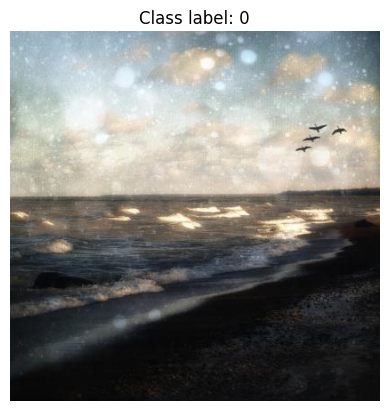

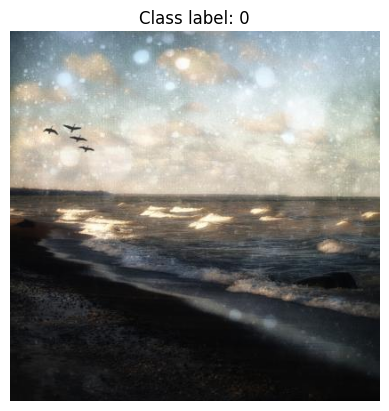

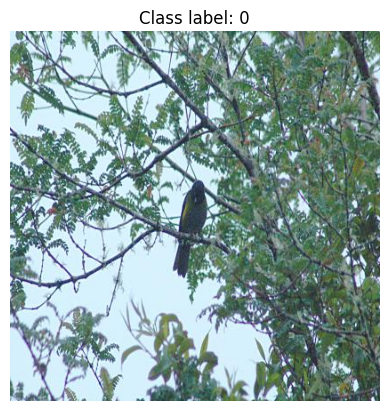

In [5]:
# Show first 3 images and their labels
for img_name in image_files[:3]:
    label_name = img_name.replace('.jpg', '.txt')
    img = Image.open(os.path.join(image_dir, img_name))
    with open(os.path.join(label_dir, label_name)) as f:
        first_line = f.readline().strip()
        class_id = int(first_line.split()[0])  # Only first value is class id
    plt.imshow(img)
    plt.title(f"Class label: {class_id}")
    plt.axis('off')
    plt.show()


In [6]:
# Set your directories
image_dir = 'data/train/images'
label_dir = 'data/train/labels'

image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpg')])
label_files = sorted([f for f in os.listdir(label_dir) if f.endswith('.txt')])
print(f"Found {len(image_files)} images and {len(label_files)} labels.")

Found 2728 images and 2728 labels.


In [7]:
# Check that every image has a matching label
missing_labels = []
for img_name in image_files:
    lbl_name = img_name.replace('.jpg', '.txt')
    if lbl_name not in label_files:
        missing_labels.append(img_name)
if missing_labels:
    print("Images without label files:", missing_labels)
else:
    print("All images have corresponding label files.")

All images have corresponding label files.


In [8]:
# Gather class IDs for all images
labels = []
corrupted_images = []
for img_name in image_files:
    lbl_name = img_name.replace('.jpg', '.txt')
    try:
        # Read class id from first value in label file
        with open(os.path.join(label_dir, lbl_name)) as f:
            class_id = int(f.readline().strip().split()[0])
        labels.append(class_id)
        # Check image can be opened
        _ = Image.open(os.path.join(image_dir, img_name))
    except Exception as e:
        print(f"Error with {img_name}: {e}")
        corrupted_images.append(img_name)

if corrupted_images:
    print("Corrupted or unreadable images:", corrupted_images)


Error with foto01538_png.rf.265030b8b67f7326eba84fa53f9e3a4c.jpg: list index out of range
Error with foto01712_png.rf.3250d162b745276efc7aa82478adbd92.jpg: list index out of range
Error with foto04293_png.rf.2ab2a380dd78593a70137ce1f9c37fe8.jpg: list index out of range
Error with foto04293_png.rf.a3d4ce93184473938d981567e4b1dcaa.jpg: list index out of range
Error with foto04496_png.rf.7180ac81a13e4371190c37f289a66b8e.jpg: list index out of range
Error with foto04496_png.rf.f4347af42d2a05c75aa71722cf3fbd54.jpg: list index out of range
Error with foto05250_png.rf.bd8d840d37def6fdf694ca62e169be81.jpg: list index out of range
Error with foto05250_png.rf.d82587244b46b9a9acc48255db01b1c9.jpg: list index out of range
Error with foto05308_png.rf.927b7d38895ac9527371a025d856bd4c.jpg: list index out of range
Error with foto05308_png.rf.b0fea0a4e64b7b51f88afdc03f35b086.jpg: list index out of range
Error with moto02060_png.rf.1ad2d81f3c66b4a2cf6f388ae408614d.jpg: list index out of range
Error with

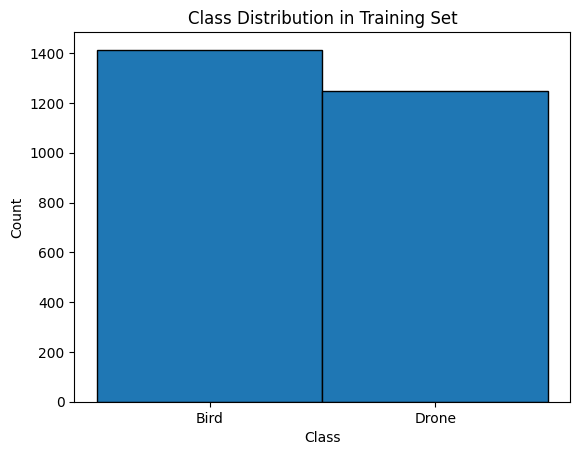

In [9]:
# Plot class distribution
plt.hist(labels, bins=[-0.5, 0.5, 1.5], edgecolor='black')
plt.xticks([0, 1], ["Bird", "Drone"])
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Class Distribution in Training Set")
plt.show()

Samples for Bird (class 0):


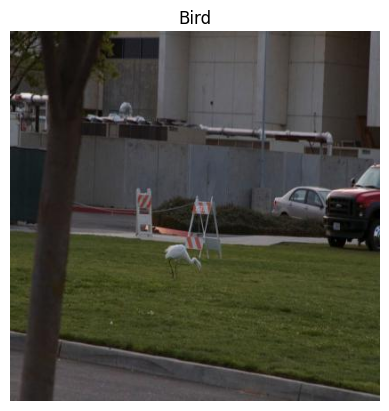

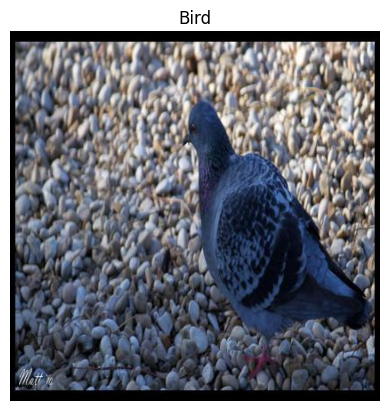

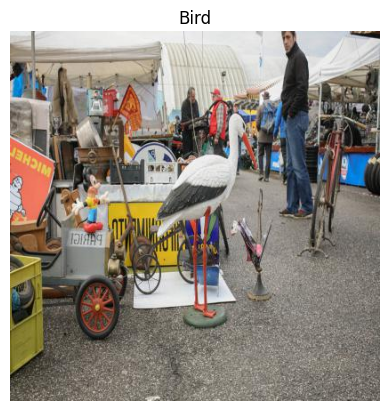

Samples for Drone (class 1):


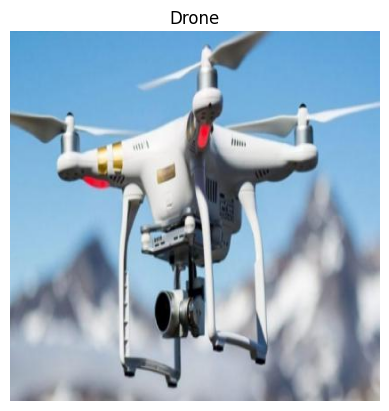

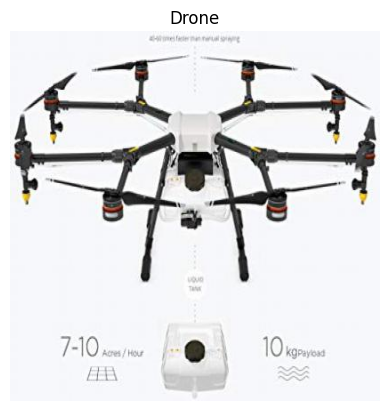

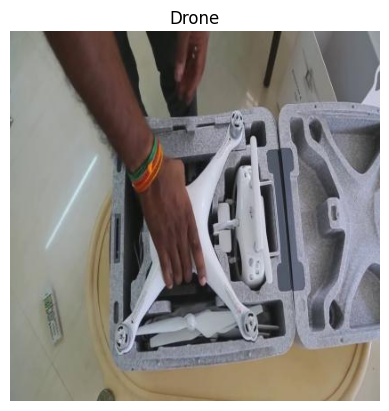

EDA and sanity checks complete. All matching, class distribution and sample visualizations done.


In [10]:
# Show random samples from each class
import random
from collections import defaultdict

samples_by_class = defaultdict(list)
for img_name, label in zip(image_files, labels):
    samples_by_class[label].append(img_name)

label_map = {0: "Bird", 1: "Drone"}
for class_id in [0, 1]:
    sample_imgs = random.sample(samples_by_class[class_id], min(3, len(samples_by_class[class_id])))
    print(f"Samples for {label_map[class_id]} (class {class_id}):")
    for img_name in sample_imgs:
        img = Image.open(os.path.join(image_dir, img_name))
        plt.imshow(img)
        plt.title(f"{label_map[class_id]}")
        plt.axis('off')
        plt.show()

print("EDA and sanity checks complete. All matching, class distribution and sample visualizations done.")